# Аналіз ефективності маркетингових каналів і кампаній інтернет-магазину на основі даних вебсесій та замовлень

**Курсова робота з дисципліни «Мови програмування для аналізу даних»**

Виконав: здобувач групи ПБСЗ-23-1 Топчій Артем

**Набір даних:** Maven Fuzzy Factory — база даних інтернет-магазину м'яких іграшок (Maven Analytics Data Playground, ліцензія Public Domain), період 19.03.2012 – 19.03.2015, 6 пов'язаних таблиць.

**Мета:** оцінити ефективність маркетингових каналів і рекламних кампаній інтернет-магазину за показниками трафіку, конверсії, виручки й маржинального прибутку та сформулювати рекомендації щодо розподілу маркетингового бюджету.

**Дослідницькі питання:**
1. Які маркетингові канали та кампанії забезпечують найбільший обсяг трафіку і найвищу конверсію сесій у замовлення?
2. Чи відрізняється ефективність каналів залежно від типу пристрою (desktop / mobile)?
3. Як змінювалися трафік, кількість замовлень, конверсія та виручка в часі і яку частку зростання забезпечили безкоштовні канали?
4. Які продукти дають найбільшу виручку й маржу та який у них рівень повернень?
5. На яких етапах воронки продажів втрачаються відвідувачі та які характеристики сесії (посадкова сторінка, пристрій, повторність візиту, день тижня, година) пов'язані з імовірністю покупки?

## 0. Підготовка середовища

In [1]:
# Імпорт бібліотек
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Налаштування відображення
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (11, 5.5), "figure.dpi": 110,
                     "axes.titlesize": 13, "axes.titleweight": "bold",
                     "font.family": "DejaVu Sans"})

# Шляхи проєкту (ноутбук запускається з папки notebooks/ або з кореня проєкту)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
FIG = BASE / "results" / "figures"
EXPORTS = BASE / "results" / "exports"
TABLEAU = BASE / "tableau"
for p in (PROCESSED, FIG, EXPORTS, TABLEAU):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Зберігає поточний графік у results/figures."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("Pandas", pd.__version__, "| Seaborn", sns.__version__)

Pandas 3.0.5 | Seaborn 0.13.2


## 1. Завантаження та первинне дослідження даних

Набір даних складається з шести таблиць, пов'язаних ключами:

| Таблиця | Зміст | Ключі |
|---|---|---|
| `website_sessions` (головна) | сесії відвідувачів сайту з UTM-мітками | PK `website_session_id`, `user_id` |
| `website_pageviews` | перегляди сторінок у межах сесій | FK `website_session_id` |
| `orders` | замовлення | PK `order_id`, FK `website_session_id`, `primary_product_id` |
| `order_items` | товарні позиції замовлень | PK `order_item_id`, FK `order_id`, `product_id` |
| `order_item_refunds` | повернення товарів | FK `order_item_id`, `order_id` |
| `products` | довідник продуктів | PK `product_id` |

In [2]:
# Завантаження CSV-файлів
sessions  = pd.read_csv(RAW / "website_sessions.csv")
pageviews = pd.read_csv(RAW / "website_pageviews.csv")
orders    = pd.read_csv(RAW / "orders.csv")
items     = pd.read_csv(RAW / "order_items.csv")
refunds   = pd.read_csv(RAW / "order_item_refunds.csv")
products  = pd.read_csv(RAW / "products.csv")

tables = {"website_sessions": sessions, "website_pageviews": pageviews, "orders": orders,
          "order_items": items, "order_item_refunds": refunds, "products": products}

overview = pd.DataFrame({name: {"рядків": df.shape[0], "стовпців": df.shape[1],
                                "пам'ять, МБ": round(df.memory_usage(deep=True).sum() / 1024**2, 1)}
                         for name, df in tables.items()}).T
overview

,рядків,стовпців,"пам'ять, МБ"
website_sessions,"472,871.00",9.00,61.60
website_pageviews,"1,188,124.00",4.00,70.30
orders,"32,313.00",8.00,2.60
order_items,"40,025.00",7.00,2.90
order_item_refunds,"1,731.00",5.00,0.10
products,4.00,3.00,0.00


In [3]:
# Перші та останні записи головної таблиці
display(sessions.head())
display(sessions.tail(3))

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
472868,472869,2015-03-19 07:55:40,394316,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
472869,472870,2015-03-19 07:56:29,394317,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
472870,472871,2015-03-19 07:59:08,394318,0,NaN,NaN,NaN,mobile,NaN


In [4]:
# Типи даних і структура головної таблиці
sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 472871 entries, 0 to 472870
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   website_session_id  472871 non-null  int64
 1   created_at          472871 non-null  str  
 2   user_id             472871 non-null  int64
 3   is_repeat_session   472871 non-null  int64
 4   utm_source          389543 non-null  str  
 5   utm_campaign        389543 non-null  str  
 6   utm_content         389543 non-null  str  
 7   device_type         472871 non-null  str  
 8   http_referer        432954 non-null  str  
dtypes: int64(3), str(6)
memory usage: 61.6 MB


In [5]:
# Типи даних інших таблиць
for name in ["orders", "order_items", "order_item_refunds", "products", "website_pageviews"]:
    print(f"--- {name} ---")
    print(tables[name].dtypes.to_string(), "\n")

--- orders ---
order_id                int64
created_at                str
website_session_id      int64
user_id                 int64
primary_product_id      int64
items_purchased         int64
price_usd             float64
cogs_usd              float64 

--- order_items ---
order_item_id        int64
created_at             str
order_id             int64
product_id           int64
is_primary_item      int64
price_usd          float64
cogs_usd           float64 

--- order_item_refunds ---
order_item_refund_id      int64
created_at                  str
order_item_id             int64
order_id                  int64
refund_amount_usd       float64 

--- products ---
product_id      int64
created_at        str
product_name      str 

--- website_pageviews ---
website_pageview_id    int64
created_at               str
website_session_id     int64
pageview_url             str 



In [6]:
# Описова статистика числових полів таблиці замовлень
orders[["items_purchased", "price_usd", "cogs_usd"]].describe()

,items_purchased,price_usd,cogs_usd
count,"32,313.00","32,313.00","32,313.00"
mean,1.24,59.99,22.36
std,0.43,17.81,6.24
min,1.00,29.99,9.49
25%,1.00,49.99,19.49
50%,1.00,49.99,19.49
75%,1.00,59.99,22.49
max,2.00,109.98,41.98


In [7]:
# Унікальні значення категоріальних ознак головної таблиці
cat_cols = ["utm_source", "utm_campaign", "utm_content", "device_type", "http_referer", "is_repeat_session"]
print(sessions[cat_cols].nunique(dropna=False).to_string(), "\n")
for col in cat_cols:
    print(f"--- {col} ---")
    print(sessions[col].value_counts(dropna=False).to_string(), "\n")

utm_source           4
utm_campaign         5
utm_content          7
device_type          2
http_referer         4
is_repeat_session    2 

--- utm_source ---
utm_source
gsearch       316035
NaN            83328
bsearch        62823
socialbook     10685 

--- utm_campaign ---
utm_campaign
nonbrand            337615
NaN                  83328
brand                41243
desktop_targeted      5590
pilot                 5095 

--- utm_content ---
utm_content
g_ad_1         282706
NaN             83328
b_ad_1          54909
g_ad_2          33329
b_ad_2           7914
social_ad_2      5590
social_ad_1      5095 

--- device_type ---
device_type
desktop    327027
mobile     145844 

--- http_referer ---
http_referer
https://www.gsearch.com       351237
https://www.bsearch.com        71032
NaN                            39917
https://www.socialbook.com     10685 

--- is_repeat_session ---
is_repeat_session
0    394318
1     78553 



**Інтерпретація.** Головна таблиця `website_sessions` містить 472 871 сесію і 9 ознак: ідентифікатори (`website_session_id`, `user_id`), дату й час (`created_at`), бінарну ознаку повторного візиту та п'ять категоріальних ознак, що описують джерело трафіку (`utm_source`, `utm_campaign`, `utm_content`, `http_referer`) і тип пристрою. Пов'язані таблиці: 1 188 124 перегляди сторінок, 32 313 замовлень, 40 025 товарних позицій, 1 731 повернення та довідник із 4 продуктів. Отже, у даних є числові (ціна, собівартість, кількість товарів), категоріальні, логічні й часові ознаки.

Дати завантажено як текст (`str`), а бінарні прапорці — як цілі числа, тому їх потрібно перетворити. Для групування придатні `utm_*`, `device_type`, `is_repeat_session` та компоненти дати; для обчислень — `price_usd`, `cogs_usd`, `items_purchased`; для об'єднання — ключі `website_session_id`, `order_id`, `order_item_id`, `product_id`. Ціни замовлень мають мінімум $29,99 і максимум $109,98, а медіана ($49,99) нижча за середнє ($59,99), тобто розподіл скошений праворуч.

## 2. Попереднє опрацювання даних

### 2.1. Пропущені значення

In [8]:
def missing_report(df):
    """Кількість і частка пропусків за стовпцями (лише стовпці з пропусками)."""
    rep = pd.DataFrame({"пропусків": df.isna().sum(), "частка, %": df.isna().mean() * 100})
    return rep[rep["пропусків"] > 0]

for name, df in tables.items():
    rep = missing_report(df)
    print(f"{name}: {'пропусків немає' if rep.empty else ''}")
    if not rep.empty:
        print(rep.to_string(), "\n")

website_sessions: 
              пропусків  частка, %
utm_source        83328      17.62
utm_campaign      83328      17.62
utm_content       83328      17.62
http_referer      39917       8.44 

website_pageviews: пропусків немає
orders: пропусків немає
order_items: пропусків немає
order_item_refunds: пропусків немає
products: пропусків немає


In [9]:
# Чи пропуски в UTM-полях збігаються в одних і тих самих рядках?
utm_na = sessions[["utm_source", "utm_campaign", "utm_content"]].isna()
print("Рядків, де всі UTM порожні:", utm_na.all(axis=1).sum())
print("Рядків, де порожні лише деякі UTM:", (utm_na.any(axis=1) & ~utm_na.all(axis=1)).sum())

# Як пов'язані пропуски UTM і реферера
pd.crosstab(sessions["utm_source"].isna(), sessions["http_referer"].fillna("(немає)"),
            rownames=["UTM відсутні"], colnames=["http_referer"])

Рядків, де всі UTM порожні: 83328
Рядків, де порожні лише деякі UTM: 0


http_referer,(немає),https://www.bsearch.com,https://www.gsearch.com,https://www.socialbook.com
UTM відсутні,,,,
False,0,62823,316035,10685
True,39917,8209,35202,0


**Інтерпретація.** Пропуски є лише в головній таблиці: 83 328 сесій (17,6 %) без UTM-міток і 39 917 сесій (8,4 %) без реферера. Усі три UTM-поля порожні одночасно, а частково заповнених рядків немає. Перехресна таблиця показує, що сесії без UTM, але з реферером gsearch/bsearch, — це перехід з безкоштовної (органічної) пошукової видачі, а сесії без UTM і без реферера — прямий захід (користувач увів адресу сайту). Отже, пропуски не є помилкою збирання даних, а несуть інформацію про канал. Видаляти такі записи недоцільно: це 17,6 % трафіку і саме безкоштовні канали. Тому пропуски замінено змістовними категоріями `none` (немає UTM) і `direct` (немає реферера); після оброблення пропусків не залишилося (289 901 → 0 порожніх комірок).

In [10]:
# Заповнення пропусків: структурні пропуски замінюємо змістовними категоріями
na_before = sessions.isna().sum().sum()

sessions["utm_source"]   = sessions["utm_source"].fillna("none")
sessions["utm_campaign"] = sessions["utm_campaign"].fillna("none")
sessions["utm_content"]  = sessions["utm_content"].fillna("none")
sessions["http_referer"] = sessions["http_referer"].fillna("direct")

na_after = sessions.isna().sum().sum()
print(f"Пропусків у website_sessions: до — {na_before:,}, після — {na_after:,}")

Пропусків у website_sessions: до — 289,901, після — 0


### 2.2. Дублікати

In [11]:
dup_report = pd.DataFrame({
    "повних дублікатів рядків": {n: df.duplicated().sum() for n, df in tables.items()},
})
pk = {"website_sessions": "website_session_id", "website_pageviews": "website_pageview_id",
      "orders": "order_id", "order_items": "order_item_id",
      "order_item_refunds": "order_item_refund_id", "products": "product_id"}
dup_report["дублікатів первинного ключа"] = {n: tables[n][k].duplicated().sum() for n, k in pk.items()}
dup_report["одна сесія — кілька замовлень"] = np.nan
dup_report.loc["orders", "одна сесія — кілька замовлень"] = orders["website_session_id"].duplicated().sum()
dup_report

,повних дублікатів рядків,дублікатів первинного ключа,одна сесія — кілька замовлень
website_sessions,0,0,NaN
website_pageviews,0,0,NaN
orders,0,0,0.00
order_items,0,0,NaN
order_item_refunds,0,0,NaN
products,0,0,NaN


In [12]:
# Профілактично видаляємо можливі дублікати (операція ідемпотентна)
before = {n: len(df) for n, df in tables.items()}
sessions  = sessions.drop_duplicates()
pageviews = pageviews.drop_duplicates()
orders    = orders.drop_duplicates()
items     = items.drop_duplicates()
refunds   = refunds.drop_duplicates()
after = {"website_sessions": len(sessions), "website_pageviews": len(pageviews), "orders": len(orders),
         "order_items": len(items), "order_item_refunds": len(refunds), "products": len(products)}
pd.DataFrame({"до": before, "після": after, "видалено": {n: before[n] - after[n] for n in before}})

,до,після,видалено
website_sessions,472871,472871,0
website_pageviews,1188124,1188124,0
orders,32313,32313,0
order_items,40025,40025,0
order_item_refunds,1731,1731,0
products,4,4,0


**Інтерпретація.** Повних дублікатів рядків і повторів первинних ключів у жодній таблиці не виявлено; кожній сесії відповідає не більше одного замовлення. Операцію `drop_duplicates()` виконано для гарантії відтворюваності: кількість записів не змінилася. Це очікувано для вивантаження з реляційної бази даних, де первинні ключі унікальні.

### 2.3. Перетворення типів даних

In [13]:
# Дати: текст -> datetime
for df in (sessions, pageviews, orders, items, refunds, products):
    df["created_at"] = pd.to_datetime(df["created_at"])

# Бінарні прапорці: int -> bool
sessions["is_repeat_session"] = sessions["is_repeat_session"].astype(bool)
items["is_primary_item"] = items["is_primary_item"].astype(bool)

# Категоріальні ознаки: str -> category (економія пам'яті та коректне групування)
for col in ["utm_source", "utm_campaign", "utm_content", "device_type", "http_referer"]:
    sessions[col] = sessions[col].astype("category")
pageviews["pageview_url"] = pageviews["pageview_url"].astype("category")
products["product_name"] = products["product_name"].astype("category")

print(sessions.dtypes.to_string())
print(f"\nПам'ять website_sessions після оптимізації: {sessions.memory_usage(deep=True).sum()/1024**2:.1f} МБ")

website_session_id             int64
created_at            datetime64[us]
user_id                        int64
is_repeat_session               bool
utm_source                  category
utm_campaign                category
utm_content                 category
device_type                 category
http_referer                category

Пам'ять website_sessions після оптимізації: 13.5 МБ


### 2.4. Перевірка коректності та узгодженості даних

In [14]:
checks = {
    "ціна замовлення ≤ 0": (orders["price_usd"] <= 0).sum(),
    "собівартість > ціни (збиткове замовлення)": (orders["cogs_usd"] > orders["price_usd"]).sum(),
    "items_purchased поза [1; 2]": (~orders["items_purchased"].between(1, 2)).sum(),
    "замовлення без відповідної сесії": (~orders["website_session_id"].isin(sessions["website_session_id"])).sum(),
    "замовлення раніше за сесію": (orders.merge(sessions[["website_session_id", "created_at"]],
                                   on="website_session_id", suffixes=("", "_s"))
                                   .eval("created_at < created_at_s")).sum(),
    "позиції без замовлення": (~items["order_id"].isin(orders["order_id"])).sum(),
    "повернення без позиції": (~refunds["order_item_id"].isin(items["order_item_id"])).sum(),
    "повернення раніше за замовлення": (refunds.merge(items[["order_item_id", "created_at"]], on="order_item_id",
                                         suffixes=("", "_i")).eval("created_at < created_at_i")).sum(),
}
# Узгодженість orders і order_items: суми та кількість позицій
agg_items = items.groupby("order_id").agg(n_items=("order_item_id", "count"),
                                           sum_price=("price_usd", "sum"), sum_cogs=("cogs_usd", "sum"))
chk = orders.set_index("order_id").join(agg_items)
checks["кількість позицій ≠ items_purchased"] = (chk["n_items"] != chk["items_purchased"]).sum()
checks["сума позицій ≠ price_usd замовлення"] = (~np.isclose(chk["sum_price"], chk["price_usd"])).sum()

# Повернення не більше ціни позиції
ref_chk = refunds.merge(items[["order_item_id", "price_usd"]], on="order_item_id")
checks["сума повернення > ціни позиції"] = (ref_chk["refund_amount_usd"] > ref_chk["price_usd"] + 1e-9).sum()
checks["часткові повернення (сума < ціни)"] = (ref_chk["refund_amount_usd"] < ref_chk["price_usd"] - 1e-9).sum()

pd.Series(checks, name="кількість записів").to_frame()

,кількість записів
ціна замовлення ≤ 0,0
собівартість > ціни (збиткове замовлення),0
items_purchased поза [1; 2],0
замовлення без відповідної сесії,0
замовлення раніше за сесію,0
позиції без замовлення,0
повернення без позиції,0
повернення раніше за замовлення,0
кількість позицій ≠ items_purchased,0
сума позицій ≠ price_usd замовлення,0


**Інтерпретація.** Перевірено 12 правил логічної узгодженості: додатність цін, відсутність збиткових замовлень, допустиму кількість товарів, наявність сесії для кожного замовлення й позиції для кожного повернення, хронологію подій, а також відповідність кількості та суми позицій у `order_items` показникам замовлення в `orders`. Порушень не виявлено. Повернення завжди здійснюються на повну вартість товару (часткових повернень немає), тому сума повернення дорівнює ціні позиції.

### 2.5. Дослідження потенційних викидів

In [15]:
def iqr_outliers(s):
    """Межі та кількість викидів за правилом 1,5·IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "нижня межа": lo, "верхня межа": hi,
                      "викидів": int(((s < lo) | (s > hi)).sum()),
                      "частка, %": ((s < lo) | (s > hi)).mean() * 100})

pd.DataFrame({"price_usd (замовлення)": iqr_outliers(orders["price_usd"]),
              "cogs_usd (замовлення)": iqr_outliers(orders["cogs_usd"])}).T

,Q1,Q3,IQR,нижня межа,верхня межа,викидів,"частка, %"
price_usd (замовлення),49.99,59.99,10.00,34.99,74.99,"8,246.00",25.52
cogs_usd (замовлення),19.49,22.49,3.00,14.99,26.99,"9,623.00",29.78


In [16]:
# Що саме потрапляє у «викиди» за ціною?
q3 = orders["price_usd"].quantile(0.75); iqr = q3 - orders["price_usd"].quantile(0.25)
pd.crosstab(orders["price_usd"] > q3 + 1.5 * iqr, orders["items_purchased"],
            rownames=["викид за IQR"], colnames=["товарів у замовленні"])

товарів у замовленні,1,2
викид за IQR,,
False,24601,0
True,0,7712


In [17]:
# Ціни окремих продуктів (позиції замовлень) — дискретний прайс-лист
items.merge(products[["product_id", "product_name"]], on="product_id") \
     .groupby("product_name", observed=True)["price_usd"].agg(["min", "max", "nunique", "count"])

,min,max,nunique,count
product_name,,,,
The Birthday Sugar Panda,45.99,45.99,1,4985
The Forever Love Bear,59.99,59.99,1,5796
The Hudson River Mini bear,29.99,29.99,1,5018
The Original Mr. Fuzzy,49.99,49.99,1,24226


**Інтерпретація.** За правилом 1,5·IQR формально «викидами» є 8 246 замовлень (25,5 %) за ціною. Перехресна таблиця показує, що всі вони (крім 534 дешевих замовлень Mini bear, які лежать нижче межі) — замовлення з двома товарами, тобто результат крос-продажу. Ціни окремих продуктів фіксовані ($29,99–59,99), тому сума замовлення приймає лише кілька дискретних значень. Ці спостереження відображають реальну бізнес-модель магазину, тому їх не видалено й не змінено — вони потрібні для аналізу середнього чека та крос-продажів. Правило IQR тут погано підходить через дискретність ціни: Q1 і медіана збігаються ($49,99).

### 2.6. Підсумок очищення

Зберігаємо очищені таблиці у `data/processed/` (формат Parquet зберігає типи даних; дублюємо головну таблицю у CSV).

In [18]:
for name, df in {"website_sessions": sessions, "orders": orders, "order_items": items,
                 "order_item_refunds": refunds, "products": products}.items():
    df.to_parquet(PROCESSED / f"{name}_clean.parquet", index=False)
print("Збережено:", sorted(p.name for p in PROCESSED.glob("*.parquet")))

Збережено: ['order_item_refunds_clean.parquet', 'order_items_clean.parquet', 'orders_clean.parquet', 'products_clean.parquet', 'sessions_enriched.parquet', 'website_sessions_clean.parquet']


## 3. Перетворення даних і створення аналітичних ознак

Нові ознаки:

| Ознака | Рівень | Призначення |
|---|---|---|
| `channel` | сесія | маркетинговий канал (платний небрендовий, брендовий, соцмережа, органічний пошук, прямий захід) — основний розріз аналізу |
| `channel_type` | сесія | платний / безкоштовний трафік |
| `year`, `quarter`, `year_month`, `weekday`, `hour` | сесія | компоненти дати для аналізу динаміки та сезонності |
| `pageviews` | сесія | глибина перегляду (кількість сторінок) |
| `is_bounce` | сесія | відмова — сесія з однією сторінкою |
| `landing_page` | сесія | посадкова сторінка (перша сторінка сесії) |
| `funnel_step`, `funnel_stage` | сесія | найглибший досягнутий етап воронки продажів (число та категорія) |
| `is_converted` | сесія | чи завершилася сесія замовленням |
| `margin_usd`, `margin_pct` | замовлення | маржинальний прибуток і рентабельність |
| `order_size` | замовлення | категорія величини замовлення |
| `is_refunded`, `net_revenue_usd` | позиція | повернення та чиста виручка |

In [19]:
# 3.1. Маркетинговий канал (логічне правило на основі UTM і реферера)
def classify_channel(df):
    conds = [
        df["utm_campaign"].eq("nonbrand"),
        df["utm_campaign"].eq("brand"),
        df["utm_source"].eq("socialbook"),
        df["utm_source"].eq("none") & df["http_referer"].ne("direct"),
        df["utm_source"].eq("none") & df["http_referer"].eq("direct"),
    ]
    choices = ["Платний пошук (nonbrand)", "Платний пошук (brand)", "Соцмережа (socialbook)",
               "Органічний пошук", "Прямий захід"]
    return np.select(conds, choices, default="Інше")

CHANNEL_ORDER = ["Платний пошук (nonbrand)", "Платний пошук (brand)", "Соцмережа (socialbook)",
                 "Органічний пошук", "Прямий захід"]
sessions["channel"] = pd.Categorical(classify_channel(sessions), categories=CHANNEL_ORDER)
sessions["channel_type"] = np.where(sessions["utm_source"].eq("none"), "Безкоштовний", "Платний")

# 3.2. Компоненти дати
sessions = sessions.assign(
    year=sessions["created_at"].dt.year,
    quarter=sessions["created_at"].dt.to_period("Q").astype(str),
    year_month=sessions["created_at"].dt.to_period("M").astype(str),
    weekday=sessions["created_at"].dt.dayofweek,          # 0 = понеділок
    hour=sessions["created_at"].dt.hour,
)

print(sessions["channel"].value_counts().to_string())
print("\nНекласифікованих сесій:", (sessions["channel"].isna()).sum())

channel
Платний пошук (nonbrand)    337615
Органічний пошук             43411
Платний пошук (brand)        41243
Прямий захід                 39917
Соцмережа (socialbook)       10685

Некласифікованих сесій: 0


In [20]:
# 3.3. Глибина перегляду, відмови, посадкова сторінка, етап воронки (агрегування таблиці переглядів)
FUNNEL = {"/products": 1, "/the-original-mr-fuzzy": 2, "/the-forever-love-bear": 2,
          "/the-birthday-sugar-panda": 2, "/the-hudson-river-mini-bear": 2, "/cart": 3,
          "/shipping": 4, "/billing": 5, "/billing-2": 5, "/thank-you-for-your-order": 6}
STAGES = ["0. Лише посадкова", "1. Каталог", "2. Сторінка товару", "3. Кошик",
          "4. Доставка", "5. Оплата", "6. Замовлення"]
pageviews["step"] = pageviews["pageview_url"].astype(str).map(FUNNEL).fillna(0).astype(int)
pv_agg = (pageviews.sort_values("website_pageview_id")
          .groupby("website_session_id")
          .agg(pageviews=("website_pageview_id", "count"),
               landing_page=("pageview_url", "first"),
               funnel_step=("step", "max")))
sessions = sessions.merge(pv_agg, on="website_session_id", how="left", validate="one_to_one")
sessions["pageviews"] = sessions["pageviews"].fillna(0).astype(int)
sessions["landing_page"] = sessions["landing_page"].astype(str).astype("category")
sessions["is_bounce"] = sessions["pageviews"].eq(1)
sessions["funnel_stage"] = pd.Categorical.from_codes(sessions["funnel_step"].astype(int), categories=STAGES)

# 3.4. Конверсія: об'єднання сесій із замовленнями (left join — зберігаємо всі сесії)
sess = sessions.merge(orders[["website_session_id", "order_id", "price_usd", "cogs_usd", "items_purchased",
                              "primary_product_id"]],
                      on="website_session_id", how="left", validate="one_to_one")
sess["is_converted"] = sess["order_id"].notna()
sess[["price_usd", "cogs_usd"]] = sess[["price_usd", "cogs_usd"]].fillna(0)
sess["margin_usd"] = sess["price_usd"] - sess["cogs_usd"]

print(f"Сесій: {len(sess):,} | із замовленням: {sess['is_converted'].sum():,} "
      f"| загальна конверсія: {sess['is_converted'].mean():.2%}")
sess[["website_session_id", "channel", "device_type", "landing_page", "pageviews", "is_bounce",
      "funnel_stage", "is_converted", "price_usd", "margin_usd"]].head()

Сесій: 472,871 | із замовленням: 32,313 | загальна конверсія: 6.83%


,website_session_id,channel,device_type,landing_page,pageviews,is_bounce,funnel_stage,is_converted,price_usd,margin_usd
0,1,Платний пошук (nonbrand),mobile,/home,1,True,0. Лише посадкова,False,0.00,0.00
1,2,Платний пошук (nonbrand),desktop,/home,1,True,0. Лише посадкова,False,0.00,0.00
2,3,Платний пошук (nonbrand),desktop,/home,1,True,0. Лише посадкова,False,0.00,0.00
3,4,Платний пошук (nonbrand),desktop,/home,1,True,0. Лише посадкова,False,0.00,0.00
4,5,Платний пошук (nonbrand),mobile,/home,1,True,0. Лише посадкова,False,0.00,0.00


In [21]:
# 3.5. Ознаки рівня замовлення
orders = orders.assign(
    margin_usd=lambda d: d["price_usd"] - d["cogs_usd"],
    margin_pct=lambda d: (d["price_usd"] - d["cogs_usd"]) / d["price_usd"] * 100,
    year_month=lambda d: d["created_at"].dt.to_period("M").astype(str),
)
orders["order_size"] = pd.cut(orders["price_usd"], bins=[0, 40, 55, 70, 200],
                              labels=["Малий (<$40)", "Середній ($40–55)", "Стандартний ($55–70)",
                                      "Великий (>$70, крос-продаж)"])
orders = orders.merge(sessions[["website_session_id", "channel", "device_type"]], on="website_session_id",
                      how="left", validate="one_to_one")

# 3.6. Ознаки рівня позиції: повернення та чиста виручка (об'єднання трьох таблиць)
items_full = (items
              .merge(products[["product_id", "product_name"]], on="product_id", how="left")
              .merge(refunds[["order_item_id", "refund_amount_usd"]], on="order_item_id", how="left"))
items_full["is_refunded"] = items_full["refund_amount_usd"].notna()
items_full["refund_amount_usd"] = items_full["refund_amount_usd"].fillna(0)
items_full["net_revenue_usd"] = items_full["price_usd"] - items_full["refund_amount_usd"]
items_full["margin_usd"] = items_full["price_usd"] - items_full["cogs_usd"]

display(orders[["order_id", "price_usd", "margin_usd", "margin_pct", "order_size", "channel"]].head())
display(orders["order_size"].value_counts().sort_index().to_frame("замовлень"))

,order_id,price_usd,margin_usd,margin_pct,order_size,channel
0,1,49.99,30.50,61.01,Середній ($40–55),Платний пошук (nonbrand)
1,2,49.99,30.50,61.01,Середній ($40–55),Платний пошук (nonbrand)
2,3,49.99,30.50,61.01,Середній ($40–55),Платний пошук (nonbrand)
3,4,49.99,30.50,61.01,Середній ($40–55),Платний пошук (nonbrand)
4,5,49.99,30.50,61.01,Середній ($40–55),Платний пошук (nonbrand)


,замовлень
order_size,
Малий (<$40),534
Середній ($40–55),20143
Стандартний ($55–70),3924
"Великий (>$70, крос-продаж)",7712


**Інтерпретація.** Створено ознаки трьох рівнів:
- **`channel`** — головна аналітична ознака: кожну сесію віднесено до одного з 5 каналів (некласифікованих сесій 0). Найбільший канал — платний небрендовий пошук (337 615 сесій);
- **ознаки дати** (`year`, `quarter`, `year_month`, `weekday`, `hour`) потрібні для аналізу динаміки та сезонності;
- **`landing_page`, `funnel_step`, `is_bounce`** отримано агрегуванням 1,19 млн переглядів сторінок — вони показують, з якої сторінки почалася сесія і на якому етапі воронки користувач зупинився;
- **`is_converted`** отримано об'єднанням сесій із замовленнями (left join зберігає всі 472 871 сесію); загальна конверсія становить 6,83 %;
- **`margin_usd`, `margin_pct`, `order_size`** описують прибутковість і розмір замовлення: 7 712 замовлень (23,9 %) — великі, з крос-продажем;
- **`is_refunded`, `net_revenue_usd`** отримано об'єднанням позицій із продуктами та поверненнями.

## 4. Статистичний та аналітичний аналіз

### 4.1. Описова статистика

In [22]:
desc = orders[["price_usd", "cogs_usd", "margin_usd", "margin_pct", "items_purchased"]].agg(
    ["count", "mean", "median", "std", "min", "max"]).T
desc["Q1"] = orders[desc.index].quantile(0.25)
desc["Q3"] = orders[desc.index].quantile(0.75)
desc["коеф. варіації, %"] = desc["std"] / desc["mean"] * 100
desc

,count,mean,median,std,min,max,Q1,Q3,"коеф. варіації, %"
price_usd,"32,313.00",59.99,49.99,17.81,29.99,109.98,49.99,59.99,29.69
cogs_usd,"32,313.00",22.36,19.49,6.24,9.49,41.98,19.49,22.49,27.91
margin_usd,"32,313.00",37.64,30.50,11.75,20.50,69.00,30.50,37.50,31.21
margin_pct,"32,313.00",62.56,61.01,2.32,61.01,68.49,61.01,63.77,3.70
items_purchased,"32,313.00",1.24,1.00,0.43,1.00,2.00,1.00,1.00,34.41


In [23]:
sess_desc = sess[["pageviews"]].describe().T
sess_desc["мода"] = sess["pageviews"].mode()[0]
sess_desc["асиметрія"] = sess["pageviews"].skew()
display(sess_desc)

kpi = pd.Series({
    "Сесій": len(sess),
    "Унікальних користувачів": sess["user_id"].nunique(),
    "Замовлень": len(orders),
    "Виручка, $": orders["price_usd"].sum(),
    "Маржинальний прибуток, $": orders["margin_usd"].sum(),
    "Сума повернень, $": refunds["refund_amount_usd"].sum(),
    "Конверсія сесія→замовлення, %": sess["is_converted"].mean() * 100,
    "Середній чек (AOV), $": orders["price_usd"].mean(),
    "Виручка на сесію (RPS), $": orders["price_usd"].sum() / len(sess),
    "Частка відмов, %": sess["is_bounce"].mean() * 100,
    "Частка повернених позицій, %": items_full["is_refunded"].mean() * 100,
}, name="значення")
kpi.to_frame()

,count,mean,std,min,25%,50%,75%,max,мода,асиметрія
pageviews,"472,871.00",2.51,1.82,1.00,1.00,2.00,3.00,7.00,1,1.17


,значення
Сесій,"472,871.00"
Унікальних користувачів,"394,318.00"
Замовлень,"32,313.00"
"Виручка, $","1,938,509.75"
"Маржинальний прибуток, $","1,216,139.50"
"Сума повернень, $","85,338.69"
"Конверсія сесія→замовлення, %",6.83
"Середній чек (AOV), $",59.99
"Виручка на сесію (RPS), $",4.10
"Частка відмов, %",44.76


**Інтерпретація.** Середній чек становить $59,99 за медіани $49,99, а коефіцієнт варіації — 29,7 %: більшість покупців купує один основний товар (Mr. Fuzzy), а середнє підвищують замовлення з крос-продажем. Рентабельність стабільна (середня маржа 62,6 %, коефіцієнт варіації 3,7 %), бо ціни й собівартість кожного продукту фіксовані. За три роки магазин отримав $1 938 510 виручки та $1 216 140 маржинального прибутку; повернення склали $85 339 (4,4 % виручки). На одну сесію припадає $4,10 виручки, а 44,8 % відвідувачів залишають сайт після першої сторінки. Розподіл кількості переглядів у сесії скошений праворуч (асиметрія 1,17, мода — 1 сторінка).

### 4.2. Групування й агрегування: ефективність каналів (питання 1)

In [24]:
def funnel_metrics(df, by):
    """Ключові маркетингові метрики за групами."""
    g = df.groupby(by, observed=True).agg(
        sessions=("website_session_id", "count"),
        orders=("is_converted", "sum"),
        revenue=("price_usd", "sum"),
        margin=("margin_usd", "sum"),
        bounce_rate=("is_bounce", "mean"),
        avg_pageviews=("pageviews", "mean"),
    )
    g["cr_pct"] = g["orders"] / g["sessions"] * 100
    g["aov"] = g["revenue"] / g["orders"]
    g["rps"] = g["revenue"] / g["sessions"]
    g["sessions_share_pct"] = g["sessions"] / g["sessions"].sum() * 100
    g["bounce_rate"] *= 100
    return g

by_channel = funnel_metrics(sess, "channel")
by_channel

,sessions,orders,revenue,margin,bounce_rate,avg_pageviews,cr_pct,aov,rps,sessions_share_pct
channel,,,,,,,,,,
Платний пошук (nonbrand),337615,22640,"1,349,977.69","845,993.50",45.58,2.49,6.71,59.63,4.00,71.40
Платний пошук (brand),41243,3212,"194,839.70","122,599.00",39.34,2.67,7.79,60.66,4.72,8.72
Соцмережа (socialbook),10685,343,"22,259.33","14,102.50",77.63,1.65,3.21,64.90,2.08,2.26
Органічний пошук,43411,3262,"196,809.19","123,699.50",39.23,2.67,7.51,60.33,4.53,9.18
Прямий захід,39917,2856,"174,623.84","109,745.00",40.63,2.61,7.15,61.14,4.37,8.44


In [25]:
# Деталізація до рівня кампанії та рекламного оголошення
by_campaign = funnel_metrics(sess[sess["utm_source"] != "none"], ["utm_source", "utm_campaign", "utm_content"])
by_campaign[["sessions", "orders", "cr_pct", "aov", "rps", "bounce_rate"]].sort_values("sessions", ascending=False)

sessions  orders  cr_pct   aov  rps  bounce_rate
utm_source utm_campaign     utm_content                                                  
gsearch    nonbrand         g_ad_1         282706   18822    6.66 59.74 3.98        44.88
bsearch    nonbrand         b_ad_1          54909    3818    6.95 59.08 4.11        49.16
gsearch    brand            g_ad_2          33329    2511    7.53 60.43 4.55        40.18
bsearch    brand            b_ad_2           7914     701    8.86 61.50 5.45        35.80
socialbook desktop_targeted social_ad_2      5590     288    5.15 64.29 3.31        69.03
           pilot            social_ad_1      5095      55    1.08 68.06 0.73        87.07

**Інтерпретація (питання 1).** Платний небрендовий пошук (gsearch і bsearch nonbrand) забезпечує 71,4 % сесій і 70 % замовлень, але має конверсію 6,71 % — нижчу за середню. Найвищу конверсію мають брендовий пошук (7,79 %) і органічний пошук (7,51 %): це користувачі, які вже знають бренд. Безкоштовні канали (органічний пошук і прямий захід) разом дали 17,6 % сесій і $371 433 виручки без витрат на рекламу. Соцмережа socialbook — найслабший канал: конверсія 3,21 % і 77,6 % відмов.

На рівні оголошень найкраще працює брендове оголошення bsearch `b_ad_2` (конверсія 8,86 %, RPS $5,45), а bsearch nonbrand конвертує краще за gsearch nonbrand (6,95 % проти 6,66 %). Пілотна кампанія socialbook `social_ad_1` практично не приносить замовлень (1,08 %, 87 % відмов). Кампанія `desktop_targeted` для desktop-аудиторії працює помітно краще (5,15 %).

### 4.3. Сортування та ранжування

In [26]:
rank_tbl = by_channel[["sessions", "cr_pct", "rps", "margin"]].copy()
for col in rank_tbl.columns:
    rank_tbl[f"ранг_{col}"] = rank_tbl[col].rank(ascending=False, method="min").astype(int)
rank_tbl["сумарний ранг"] = rank_tbl.filter(like="ранг_").sum(axis=1)
display(rank_tbl.sort_values("сумарний ранг"))

print("Топ-3 оголошення за конверсією (мін. 1000 сесій):")
display(by_campaign[by_campaign["sessions"] >= 1000].nlargest(3, "cr_pct")[["sessions", "cr_pct", "rps"]])
print("Найслабші 3 оголошення за конверсією (мін. 1000 сесій):")
display(by_campaign[by_campaign["sessions"] >= 1000].nsmallest(3, "cr_pct")[["sessions", "cr_pct", "rps"]])

,sessions,cr_pct,rps,margin,ранг_sessions,ранг_cr_pct,ранг_rps,ранг_margin,сумарний ранг
channel,,,,,,,,,
Платний пошук (brand),41243,7.79,4.72,"122,599.00",3,1,1,3,8
Органічний пошук,43411,7.51,4.53,"123,699.50",2,2,2,2,8
Платний пошук (nonbrand),337615,6.71,4.00,"845,993.50",1,4,4,1,10
Прямий захід,39917,7.15,4.37,"109,745.00",4,3,3,4,14
Соцмережа (socialbook),10685,3.21,2.08,"14,102.50",5,5,5,5,20


Топ-3 оголошення за конверсією (мін. 1000 сесій):


,,,sessions,cr_pct,rps
utm_source,utm_campaign,utm_content,,,
bsearch,brand,b_ad_2,7914,8.86,5.45
gsearch,brand,g_ad_2,33329,7.53,4.55
bsearch,nonbrand,b_ad_1,54909,6.95,4.11


Найслабші 3 оголошення за конверсією (мін. 1000 сесій):


sessions  cr_pct  rps
utm_source utm_campaign     utm_content                       
socialbook pilot            social_ad_1      5095    1.08 0.73
           desktop_targeted social_ad_2      5590    5.15 3.31
gsearch    nonbrand         g_ad_1         282706    6.66 3.98

### 4.4. Зведені таблиці: канал × пристрій (питання 2)

In [27]:
pivot_cr = sess.pivot_table(index="channel", columns="device_type", values="is_converted",
                            aggfunc="mean", observed=True) * 100
pivot_cr["різниця desktop − mobile, п.п."] = pivot_cr["desktop"] - pivot_cr["mobile"]
pivot_cr["desktop / mobile, разів"] = pivot_cr["desktop"] / pivot_cr["mobile"]
display(pivot_cr.round(2))

pivot_sessions = pd.crosstab(sess["channel"], sess["device_type"], normalize="index") * 100
display(pivot_sessions.round(1).rename(columns=lambda c: f"частка {c}, %"))

device_type,desktop,mobile,"різниця desktop − mobile, п.п.","desktop / mobile, разів"
channel,,,,
Платний пошук (nonbrand),8.09,3.18,4.91,2.55
Платний пошук (brand),10.37,3.01,7.36,3.44
Соцмережа (socialbook),4.99,0.83,4.16,6.01
Органічний пошук,9.96,2.94,7.02,3.39
Прямий захід,9.81,3.44,6.37,2.85


device_type,"частка desktop, %","частка mobile, %"
channel,,
Платний пошук (nonbrand),71.80,28.20
Платний пошук (brand),65.00,35.00
Соцмережа (socialbook),57.20,42.80
Органічний пошук,65.20,34.80
Прямий захід,58.30,41.70


In [28]:
# Загальні показники за пристроями
by_device = funnel_metrics(sess, "device_type")
by_device[["sessions", "sessions_share_pct", "orders", "cr_pct", "aov", "rps", "bounce_rate"]]

,sessions,sessions_share_pct,orders,cr_pct,aov,rps,bounce_rate
device_type,,,,,,,
desktop,327027,69.16,27805,8.50,59.91,5.09,41.19
mobile,145844,30.84,4508,3.09,60.50,1.87,52.75


**Інтерпретація (питання 2).** Тип пристрою впливає на результат сильніше, ніж канал. Desktop дає 69,2 % сесій, але 86 % замовлень: конверсія на desktop — 8,50 %, на mobile — 3,09 % (у 2,75 раза нижча), а відмов на mobile більше (52,8 % проти 41,2 %). Розрив зберігається в усіх каналах — від 2,6 раза в небрендовому пошуку до 6 разів у соцмережі. Середній чек майже однаковий ($59,91 і $60,50), тобто проблема мобільних користувачів не в сумі покупки, а в тому, що вони рідше доходять до оформлення замовлення. Найвища конверсія в усьому наборі — брендовий пошук на desktop (10,37 %).

### 4.5. Аналіз динаміки (питання 3)

In [29]:
# Помісячна динаміка (resample) — береміо повні місяці: квітень 2012 – лютий 2015
monthly = (sess.set_index("created_at")
           .resample("MS")
           .agg({"website_session_id": "count", "is_converted": "sum", "price_usd": "sum", "margin_usd": "sum"})
           .rename(columns={"website_session_id": "sessions", "is_converted": "orders",
                            "price_usd": "revenue", "margin_usd": "margin"}))
monthly = monthly.loc["2012-04-01":"2015-02-01"]
monthly["cr_pct"] = monthly["orders"] / monthly["sessions"] * 100
monthly["rps"] = monthly["revenue"] / monthly["sessions"]
monthly["sessions_roll3"] = monthly["sessions"].rolling(3).mean()
monthly["cr_roll3"] = monthly["cr_pct"].rolling(3).mean()
monthly.head(6)

,sessions,orders,revenue,margin,cr_pct,rps,sessions_roll3,cr_roll3
created_at,,,,,,,,
2012-04-01,3734,99,"4,949.01","3,019.50",2.65,1.33,NaN,NaN
2012-05-01,3736,108,"5,398.92","3,294.00",2.89,1.45,NaN,NaN
2012-06-01,3963,140,"6,998.60","4,270.00",3.53,1.77,"3,811.00",3.02
2012-07-01,4249,169,"8,448.31","5,154.50",3.98,1.99,"3,982.67",3.47
2012-08-01,6097,228,"11,397.72","6,954.00",3.74,1.87,"4,769.67",3.75
2012-09-01,6546,287,"14,347.13","8,753.50",4.38,2.19,"5,630.67",4.03


In [30]:
# Квартальна динаміка з темпами приросту (повні квартали 2012Q2 – 2014Q4)
quarterly = (sess[(sess["created_at"] >= "2012-04-01") & (sess["created_at"] < "2015-01-01")]
             .groupby("quarter").agg(sessions=("website_session_id", "count"), orders=("is_converted", "sum"),
                                     revenue=("price_usd", "sum")))
quarterly["cr_pct"] = quarterly["orders"] / quarterly["sessions"] * 100
quarterly["aov"] = quarterly["revenue"] / quarterly["orders"]
quarterly["rps"] = quarterly["revenue"] / quarterly["sessions"]
quarterly["приріст сесій, % (кв/кв)"] = quarterly["sessions"].pct_change() * 100
quarterly

,sessions,orders,revenue,cr_pct,aov,rps,"приріст сесій, % (кв/кв)"
quarter,,,,,,,
2012Q2,11433,347,"17,346.53",3.04,49.99,1.52,NaN
2012Q3,16892,684,"34,193.16",4.05,49.99,2.02,47.75
2012Q4,32266,1495,"74,735.05",4.63,49.99,2.32,91.01
2013Q1,19833,1273,"66,377.27",6.42,52.14,3.35,-38.53
2013Q2,24745,1718,"88,542.82",6.94,51.54,3.58,24.77
2013Q3,27663,1840,"95,191.54",6.65,51.73,3.44,11.79
2013Q4,40540,2616,"143,136.24",6.45,54.72,3.53,46.55
2014Q1,46779,3069,"190,771.14",6.56,62.16,4.08,15.39
2014Q2,53129,3848,"247,711.95",7.24,64.37,4.66,13.57


In [31]:
# Частка безкоштовного трафіку за роками (crosstab)
share_type = pd.crosstab(sess["year"], sess["channel_type"], normalize="index") * 100
share_channel = pd.crosstab(sess["year"], sess["channel"], normalize="index") * 100
display(share_type.round(1))
display(share_channel.round(1))

# Порівняння однакових періодів (Q4 2012 vs Q4 2014) за каналами
q_cmp = (sess[sess["quarter"].isin(["2012Q4", "2014Q4"])]
         .pivot_table(index="channel", columns="quarter", values="website_session_id",
                      aggfunc="count", observed=True))
q_cmp["зростання, разів"] = q_cmp["2014Q4"] / q_cmp["2012Q4"]
q_cmp

channel_type,Безкоштовний,Платний
year,,
2012,9.20,90.80
2013,15.10,84.90
2014,19.50,80.50
2015,23.20,76.80


channel,Платний пошук (nonbrand),Платний пошук (brand),Соцмережа (socialbook),Органічний пошук,Прямий захід
year,,,,,
2012,86.20,4.60,0.00,4.80,4.50
2013,77.40,7.50,0.00,7.90,7.20
2014,66.20,9.70,4.60,10.20,9.40
2015,65.40,11.40,0.00,12.10,11.10


quarter,2012Q4,2014Q4,"зростання, разів"
channel,,,
Платний пошук (nonbrand),"27,209.00","49,644.00",1.82
Платний пошук (brand),"1,656.00","7,574.00",4.57
Соцмережа (socialbook),NaN,"4,323.00",NaN
Органічний пошук,"1,744.00","7,718.00",4.43
Прямий захід,"1,657.00","7,114.00",4.29


In [32]:
# Сезонність: день тижня × година (конверсія та середній трафік)
WD = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"]
wd_tbl = sess.groupby("weekday").agg(sessions=("website_session_id", "count"), cr=("is_converted", "mean"))
wd_tbl["cr"] *= 100
wd_tbl.index = WD
display(wd_tbl.T.round(2))

hour_tbl = sess.groupby("hour").agg(sessions=("website_session_id", "count"), cr=("is_converted", "mean"))
hour_tbl["cr"] *= 100
print("Пікові години за трафіком:", hour_tbl["sessions"].nlargest(3).index.tolist())
print("Мінімальні години за трафіком:", hour_tbl["sessions"].nsmallest(3).index.tolist())

,Пн,Вт,Ср,Чт,Пт,Сб,Нд
sessions,"83,307.00","76,216.00","82,367.00","77,987.00","81,187.00","35,221.00","36,586.00"
cr,6.78,6.97,6.68,6.95,6.86,6.54,6.99


Пікові години за трафіком: [12, 11, 15]
Мінімальні години за трафіком: [3, 4, 5]


**Інтерпретація (питання 3).** За період спостереження бізнес стабільно зростав: кількість сесій у місяць збільшилася з 3 734 (квітень 2012) до 23 778 (лютий 2015), замовлень — з 99 до 2 067, виручка — з $4 949 до $129 133. Конверсія зросла з 2,65 % до 8,69 %, а виручка на сесію — з $1,33 до $5,43. Отже, зростання забезпечено не лише збільшенням трафіку, а й підвищенням його якості.

Простежується сезонність: у листопаді–грудні трафік і продажі різко зростають (пік — грудень 2014, 29 722 сесії), а в січні–березні спадають (у 2013Q1 трафік знизився на 38,5 % порівняно з 2012Q4).

Частка безкоштовного трафіку зросла з 9,2 % у 2012 р. до 23,2 % у 2015 р. Порівняння четвертих кварталів 2012 і 2014 рр. показує, що органічний пошук, прямий захід і брендовий пошук зросли в 4,3–4,6 раза, а небрендовий платний пошук — лише в 1,8 раза. Безкоштовні канали забезпечили 26 % приросту сесій. Це свідчить про формування впізнаваності бренду й зменшення залежності від платної реклами.

У вихідні трафік удвічі нижчий, ніж у будні (≈ 35–37 тис. проти 76–83 тис. сесій), а пікові години — 11:00–15:00. Конверсія ж за днями тижня майже не змінюється (6,5–7,0 %).

### 4.6. Продуктовий аналіз і повернення (питання 4)

In [33]:
by_product = items_full.groupby("product_name", observed=True).agg(
    items_sold=("order_item_id", "count"),
    revenue=("price_usd", "sum"),
    margin=("margin_usd", "sum"),
    refunds=("is_refunded", "sum"),
    refund_amount=("refund_amount_usd", "sum"),
    as_primary=("is_primary_item", "mean"),
)
by_product["margin_pct"] = by_product["margin"] / by_product["revenue"] * 100
by_product["refund_rate_pct"] = by_product["refunds"] / by_product["items_sold"] * 100
by_product["revenue_share_pct"] = by_product["revenue"] / by_product["revenue"].sum() * 100
by_product["as_primary"] *= 100
by_product = by_product.sort_values("revenue", ascending=False)
by_product["ранг за маржею"] = by_product["margin"].rank(ascending=False).astype(int)
by_product

,items_sold,revenue,margin,refunds,refund_amount,as_primary,margin_pct,refund_rate_pct,revenue_share_pct,ранг за маржею
product_name,,,,,,,,,,
The Original Mr. Fuzzy,24226,"1,211,057.74","738,893.00",1237,"61,837.63",98.49,61.01,5.11,62.47,1
The Forever Love Bear,5796,"347,702.04","217,350.00",129,"7,738.71",82.87,62.51,2.23,17.94,2
The Birthday Sugar Panda,4985,"229,260.15","157,027.50",301,"13,842.99",61.54,68.49,6.04,11.83,3
The Hudson River Mini bear,5018,"150,489.82","102,869.00",64,"1,919.36",11.58,68.36,1.28,7.76,4


In [34]:
# Крос-продажі: частка замовлень із двома товарами за роками
orders["year"] = orders["created_at"].dt.year
xsell = orders.groupby("year").agg(orders=("order_id", "count"),
                                   cross_sell_share=("items_purchased", lambda s: (s > 1).mean() * 100),
                                   aov=("price_usd", "mean"))
display(xsell)

# Повернення за роками й продуктами (pivot_table)
items_full["year"] = items_full["created_at"].dt.year
refund_pivot = items_full.pivot_table(index="product_name", columns="year", values="is_refunded",
                                      aggfunc="mean", observed=True) * 100
refund_pivot.round(2)

,orders,cross_sell_share,aov
year,,,
2012,2586,0.00,49.99
2013,7447,2.23,52.81
2014,16860,33.93,63.80
2015,5420,33.67,62.80


year,2012,2013,2014,2015
product_name,,,,
The Birthday Sugar Panda,NaN,7.19,5.95,6.17
The Forever Love Bear,NaN,2.19,2.27,2.14
The Hudson River Mini bear,NaN,NaN,1.33,1.14
The Original Mr. Fuzzy,6.88,4.83,5.31,3.53


**Інтерпретація (питання 4).** Флагманський продукт The Original Mr. Fuzzy дає 62,5 % виручки та 60,8 % маржі, але має одну з найнижчих рентабельностей (61 %) і високий рівень повернень (5,1 %). Найвищий рівень повернень — у The Birthday Sugar Panda (6,0 %), найнижчий — у The Hudson River Mini bear (1,3 %). Mini bear найрентабельніший (68,4 %) і в 88 % випадків купується як додатковий товар, тобто працює як інструмент крос-продажу.

Після запуску крос-продажу частка замовлень із двома товарами зросла з 0 % у 2012 р. до 33,9 % у 2014 р., а середній чек — з $49,99 до $63,80. Частка повернень Mr. Fuzzy знизилася з 6,9 % у 2012 р. до 3,5 % у 2015 р., що може свідчити про покращення якості продукту або постачальника.

### 4.7. Воронка продажів, посадкові сторінки та взаємозв'язки (питання 5)

In [35]:
# Воронка: частка сесій, що дійшли щонайменше до кожного етапу, за типом пристрою
def funnel_table(df):
    reach = pd.DataFrame({stage: (df["funnel_step"] >= i).mean() * 100 for i, stage in enumerate(STAGES)},
                         index=["досягли етапу, %"]).T
    reach["перехід з попереднього, %"] = reach["досягли етапу, %"] / reach["досягли етапу, %"].shift(1) * 100
    return reach

funnel_dev = pd.concat({dev: funnel_table(g) for dev, g in sess.groupby("device_type", observed=True)}, axis=1)
funnel_dev.round(2)

desktop                                     mobile                          
                   досягли етапу, % перехід з попереднього, % досягли етапу, % перехід з попереднього, %
0. Лише посадкова            100.00                       NaN           100.00                       NaN
1. Каталог                    58.81                     58.81            47.25                     47.25
2. Сторінка товару            49.91                     84.86            32.23                     68.21
3. Кошик                      22.98                     46.05            13.57                     42.12
4. Доставка                   16.11                     70.11             8.09                     59.56
5. Оплата                     13.37                     82.98             5.72                     70.69
6. Замовлення                  8.50                     63.59             3.09                     54.08

In [36]:
# Конверсія за посадковими сторінками (A/B-тести лендингів)
by_landing = sess.groupby("landing_page", observed=True).agg(
    sessions=("website_session_id", "count"), first_seen=("created_at", "min"), last_seen=("created_at", "max"),
    bounce_rate=("is_bounce", "mean"), cr=("is_converted", "mean"))
by_landing[["bounce_rate", "cr"]] *= 100
by_landing["first_seen"] = by_landing["first_seen"].dt.date
by_landing["last_seen"] = by_landing["last_seen"].dt.date
display(by_landing.sort_values("cr", ascending=False))

by_repeat = sess.groupby("is_repeat_session").agg(sessions=("website_session_id", "count"),
                                                  cr=("is_converted", "mean"), rps=("price_usd", "mean"),
                                                  bounce=("is_bounce", "mean"))
by_repeat[["cr", "bounce"]] *= 100
by_repeat.index = ["Перший візит", "Повторний візит"]
display(by_repeat)

,sessions,first_seen,last_seen,bounce_rate,cr
landing_page,,,,,
/lander-5,68166,2014-08-02,2015-03-19,36.87,10.17
/lander-2,131170,2013-01-14,2014-12-27,45.17,7.72
/lander-4,9385,2014-02-02,2014-04-19,51.69,7.54
/home,137576,2012-03-19,2015-03-19,41.68,7.06
/lander-1,47574,2012-06-19,2013-03-10,53.24,4.53
/lander-3,79000,2013-07-09,2015-03-19,50.29,3.39


,sessions,cr,rps,bounce
Перший візит,394318,6.64,3.97,46.30
Повторний візит,78553,7.83,4.74,37.03


In [37]:
# Кореляції між ознаками сесії (для бінарних ознак коефіцієнт Пірсона = точково-бісеріальний / φ)
corr_df = pd.DataFrame({
    "конверсія": sess["is_converted"],
    "відмова": sess["is_bounce"],
    "повторний візит": sess["is_repeat_session"],
    "мобільний": sess["device_type"].eq("mobile"),
    "платний канал": sess["channel_type"].eq("Платний"),
    "година": sess["hour"],
    "день тижня": sess["weekday"],
}).astype(float)
corr_session = corr_df.corr()
display(corr_session.round(3))

# Кореляції помісячних показників
corr_month = monthly[["sessions", "orders", "revenue", "cr_pct", "rps"]].corr()
corr_month.round(3)

,конверсія,відмова,повторний візит,мобільний,платний канал,година,день тижня
конверсія,1.00,-0.24,0.02,-0.10,-0.01,-0.00,0.00
відмова,-0.24,1.00,-0.07,0.11,0.04,-0.00,-0.00
повторний візит,0.02,-0.07,1.00,0.06,-0.57,0.00,0.00
мобільний,-0.10,0.11,0.06,1.00,-0.07,0.00,0.00
платний канал,-0.01,0.04,-0.57,-0.07,1.00,0.00,-0.00
година,-0.00,-0.00,0.00,0.00,0.00,1.00,-0.00
день тижня,0.00,-0.00,0.00,0.00,-0.00,-0.00,1.00


,sessions,orders,revenue,cr_pct,rps
sessions,1.00,0.98,0.98,0.74,0.86
orders,0.98,1.00,1.00,0.80,0.90
revenue,0.98,1.00,1.00,0.78,0.90
cr_pct,0.74,0.80,0.78,1.00,0.96
rps,0.86,0.90,0.90,0.96,1.00


**Інтерпретація (питання 5).** Найбільше відвідувачів втрачається на перших етапах воронки. На desktop до каталогу переходить 58,8 % сесій, на mobile — лише 47,2 %. Найбільші втрати — між сторінкою товару й кошиком: туди переходить лише 46 % відвідувачів на desktop і 42 % на mobile. На mobile гірше працює кожен крок, а особливо оформлення (з оплати до замовлення переходить 54 % проти 64 % на desktop).

Найвищу конверсію серед посадкових сторінок має `/lander-5` (10,17 %, 36,9 % відмов), найнижчу — `/lander-3` (3,39 %). Однак лендинги не можна порівнювати напряму: `/lander-3` показувався лише мобільним користувачам, `/lander-4` і `/lander-5` — лише desktop, а `/lander-5` працював у пізніший період, коли загальна конверсія сайту вже була вищою. Повторні візити конвертують краще за перші (7,83 % проти 6,64 %) і дають більше виручки на сесію ($4,74 проти $3,97).

Кореляційний аналіз підтверджує ці висновки: конверсія найсильніше (обернено) пов'язана з відмовою (r = −0,24) і з мобільним пристроєм (r = −0,10). Година й день тижня з конверсією не корелюють (|r| < 0,01). Сильний обернений зв'язок між повторним візитом і платним каналом (r = −0,57) пояснюється тим, що повторні відвідувачі зазвичай приходять безкоштовно — через брендовий пошук або напряму. На місячному рівні виручка майже повністю визначається кількістю сесій (r = 0,98), але й конверсія з часом зростала разом із трафіком (r = 0,74). Кореляція не доводить причинно-наслідкового зв'язку: обидва показники могли рости під впливом спільних чинників (покращення сайту, нові продукти).

## 5. Візуалізація даних

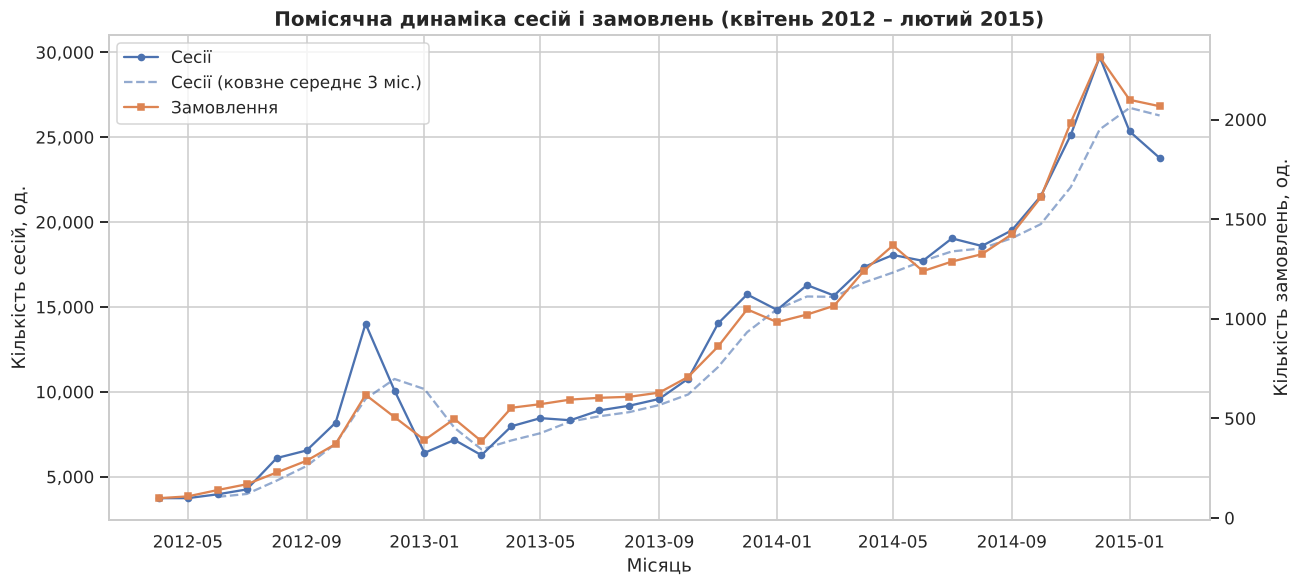

In [38]:
# Рис. 1. Динаміка сесій і замовлень по місяцях
fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax1.plot(monthly.index, monthly["sessions"], color="#4C72B0", marker="o", ms=4, label="Сесії")
ax1.plot(monthly.index, monthly["sessions_roll3"], color="#4C72B0", ls="--", alpha=.6, label="Сесії (ковзне середнє 3 міс.)")
ax1.set_ylabel("Кількість сесій, од.")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["orders"], color="#DD8452", marker="s", ms=4, label="Замовлення")
ax2.set_ylabel("Кількість замовлень, од.")
ax2.grid(False)
ax1.set_title("Помісячна динаміка сесій і замовлень (квітень 2012 – лютий 2015)")
ax1.set_xlabel("Місяць")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
save_fig("01_monthly_sessions_orders"); plt.show()

**Інтерпретація графіка.** Обидві криві мають висхідний тренд із сезонними піками в листопаді–грудні та спадом у січні–березні. Після 2013 р. крива замовлень зростає швидше за криву сесій, тобто конверсія підвищувалася. Ковзне середнє за 3 місяці згладжує сезонні коливання й показує стійке зростання.

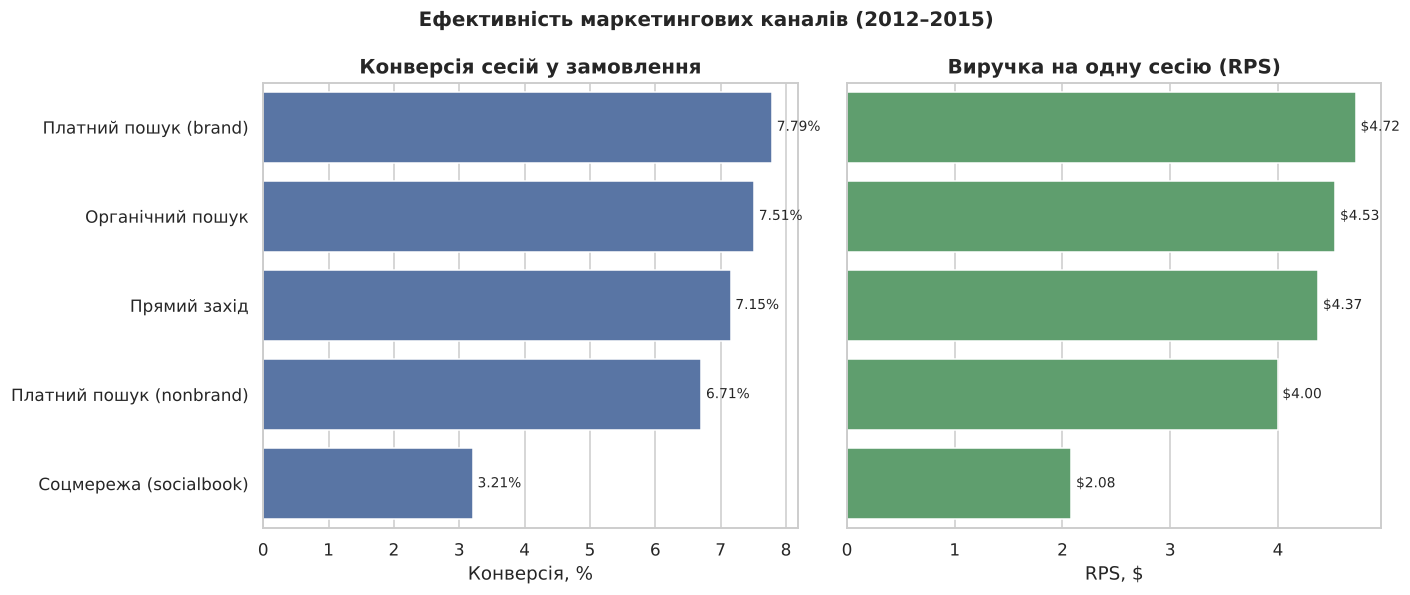

In [39]:
# Рис. 2. Конверсія і виручка на сесію за каналами
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
order_idx = by_channel.sort_values("cr_pct", ascending=False).index
sns.barplot(x=by_channel.loc[order_idx, "cr_pct"], y=order_idx.astype(str), ax=axes[0], color="#4C72B0")
axes[0].set_title("Конверсія сесій у замовлення")
axes[0].set_xlabel("Конверсія, %"); axes[0].set_ylabel("")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_width():.2f}%", (p.get_width(), p.get_y() + p.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
sns.barplot(x=by_channel.loc[order_idx, "rps"], y=order_idx.astype(str), ax=axes[1], color="#55A868")
axes[1].set_title("Виручка на одну сесію (RPS)")
axes[1].set_xlabel("RPS, $"); axes[1].set_ylabel(""); axes[1].set_yticklabels([])
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_width():.2f}", (p.get_width(), p.get_y() + p.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
fig.suptitle("Ефективність маркетингових каналів (2012–2015)", fontweight="bold", fontsize=13)
save_fig("02_channel_cr_rps"); plt.show()

**Інтерпретація графіка.** Канали, у яких користувач уже знає бренд (брендовий, органічний пошук і прямий захід), мають найвищу конверсію й виручку на сесію. Небрендовий платний пошук поступається їм, хоча забезпечує більшість трафіку. Соцмережа socialbook найменш ефективна за обома показниками — її RPS ($2,08) удвічі нижчий за середній.

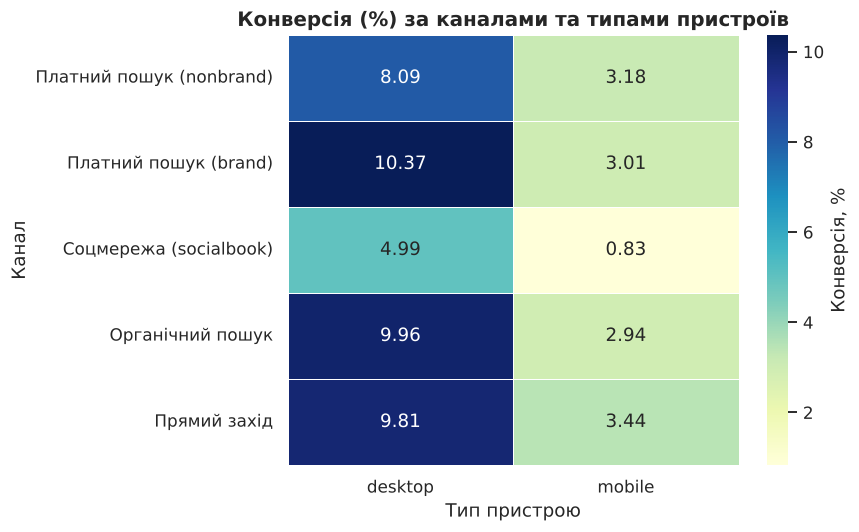

In [40]:
# Рис. 3. Теплова карта конверсії: канал × пристрій
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_cr[["desktop", "mobile"]], annot=True, fmt=".2f", cmap="YlGnBu",
            cbar_kws={"label": "Конверсія, %"}, linewidths=.5, ax=ax)
ax.set_title("Конверсія (%) за каналами та типами пристроїв")
ax.set_xlabel("Тип пристрою"); ax.set_ylabel("Канал")
save_fig("03_heatmap_channel_device"); plt.show()

**Інтерпретація графіка.** Теплова карта показує, що різниця між пристроями більша за різницю між каналами: усі комірки desktop мають конверсію 5–10 %, а mobile — 0,8–3,4 %. Отже, оптимізація мобільної версії сайту може дати більший ефект, ніж перерозподіл бюджету між каналами.

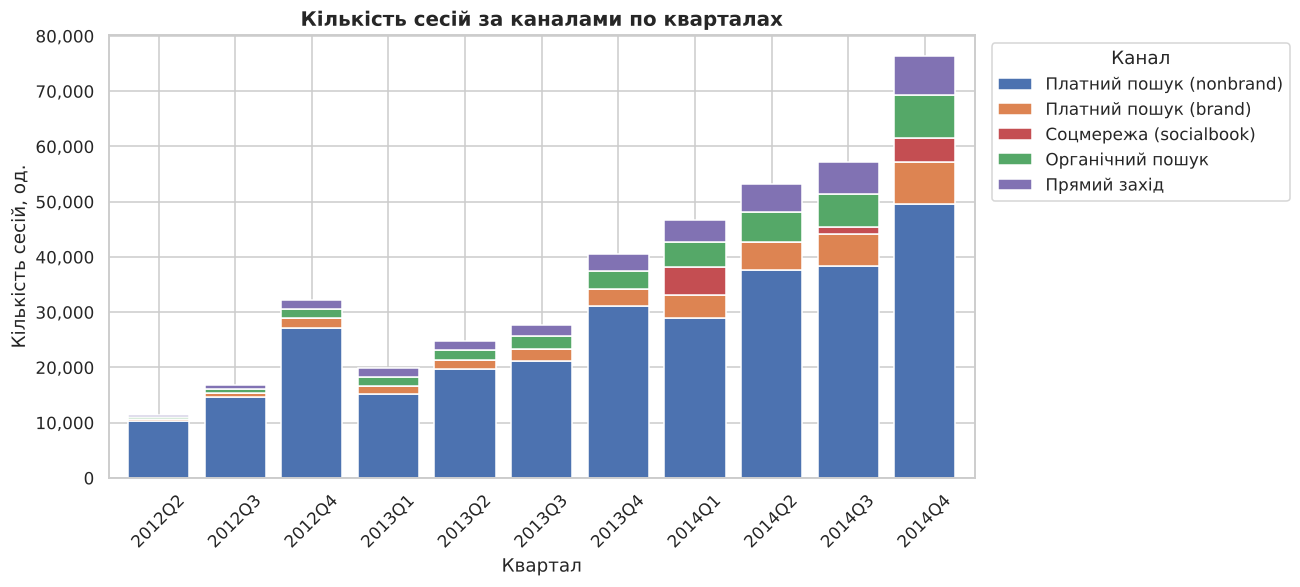

In [41]:
# Рис. 4. Структура трафіку за каналами по кварталах (накопичувальна стовпчикова діаграма)
q_struct = (sess[(sess["created_at"] >= "2012-04-01") & (sess["created_at"] < "2015-01-01")]
            .pivot_table(index="quarter", columns="channel", values="website_session_id",
                         aggfunc="count", observed=True))
ax = q_struct.plot(kind="bar", stacked=True, figsize=(12, 5.5), width=.8,
                   color=["#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8172B3"])
ax.set_title("Кількість сесій за каналами по кварталах")
ax.set_xlabel("Квартал"); ax.set_ylabel("Кількість сесій, од.")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Канал", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=45)
save_fig("04_quarterly_channel_structure"); plt.show()

**Інтерпретація графіка.** На початку періоду майже весь трафік давав небрендовий пошук. З часом зростає частка брендового, органічного та прямого трафіку (оранжевий, зелений і фіолетовий сегменти). Кампанія в соцмережі (червоний сегмент) працювала лише у 2014 р.

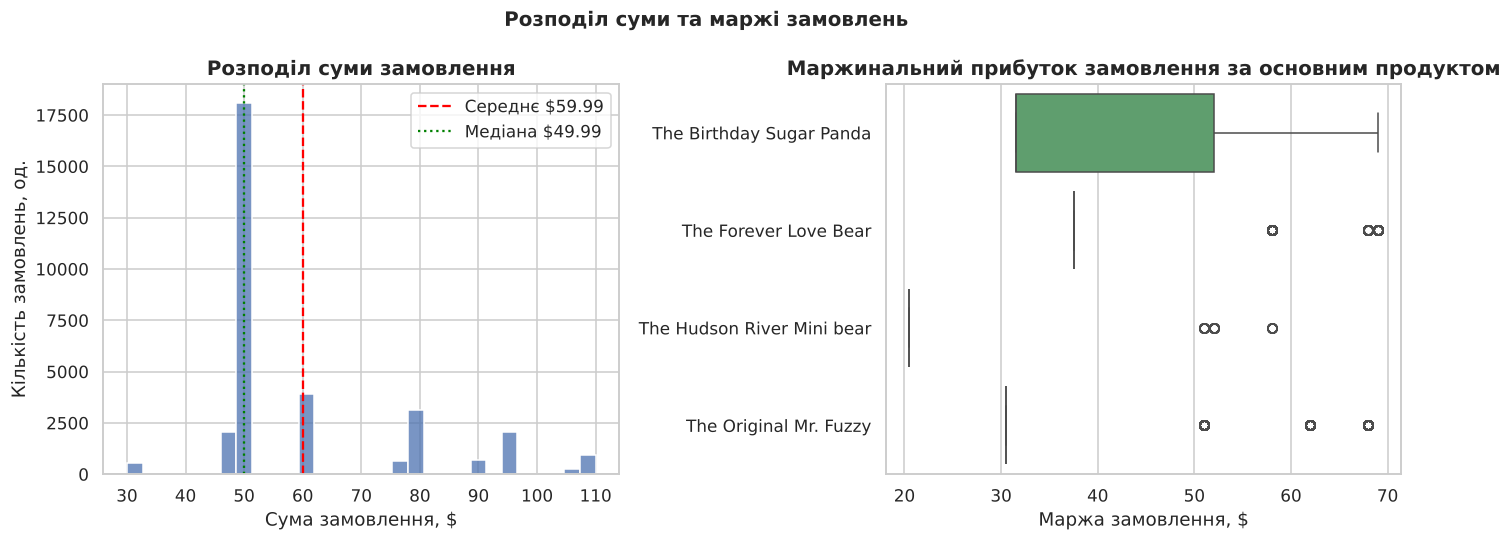

In [42]:
# Рис. 5. Розподіл суми замовлення (гістограма) та маржа за основним продуктом (boxplot)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(orders["price_usd"], bins=30, ax=axes[0], color="#4C72B0")
axes[0].axvline(orders["price_usd"].mean(), color="red", ls="--", label=f"Середнє ${orders['price_usd'].mean():.2f}")
axes[0].axvline(orders["price_usd"].median(), color="green", ls=":", label=f"Медіана ${orders['price_usd'].median():.2f}")
axes[0].set_title("Розподіл суми замовлення")
axes[0].set_xlabel("Сума замовлення, $"); axes[0].set_ylabel("Кількість замовлень, од.")
axes[0].legend()

ord_prod = orders.merge(products[["product_id", "product_name"]], left_on="primary_product_id", right_on="product_id")
sns.boxplot(data=ord_prod, x="margin_usd", y="product_name", ax=axes[1], color="#55A868")
axes[1].set_title("Маржинальний прибуток замовлення за основним продуктом")
axes[1].set_xlabel("Маржа замовлення, $"); axes[1].set_ylabel("")
fig.suptitle("Розподіл суми та маржі замовлень", fontweight="bold", fontsize=13)
save_fig("05_order_value_distribution"); plt.show()

**Інтерпретація графіка.** Розподіл суми замовлення дискретний і мультимодальний: основний пік — $49,99 (один Mr. Fuzzy), менші піки — ціни інших продуктів і сум двох товарів. Тому середнє ($59,99) суттєво перевищує медіану ($49,99). На діаграмі розмаху найбільший розкид маржі мають замовлення Birthday Sugar Panda, які найчастіше доповнюються іншим товаром; точки праворуч — замовлення з крос-продажем, а не помилки.

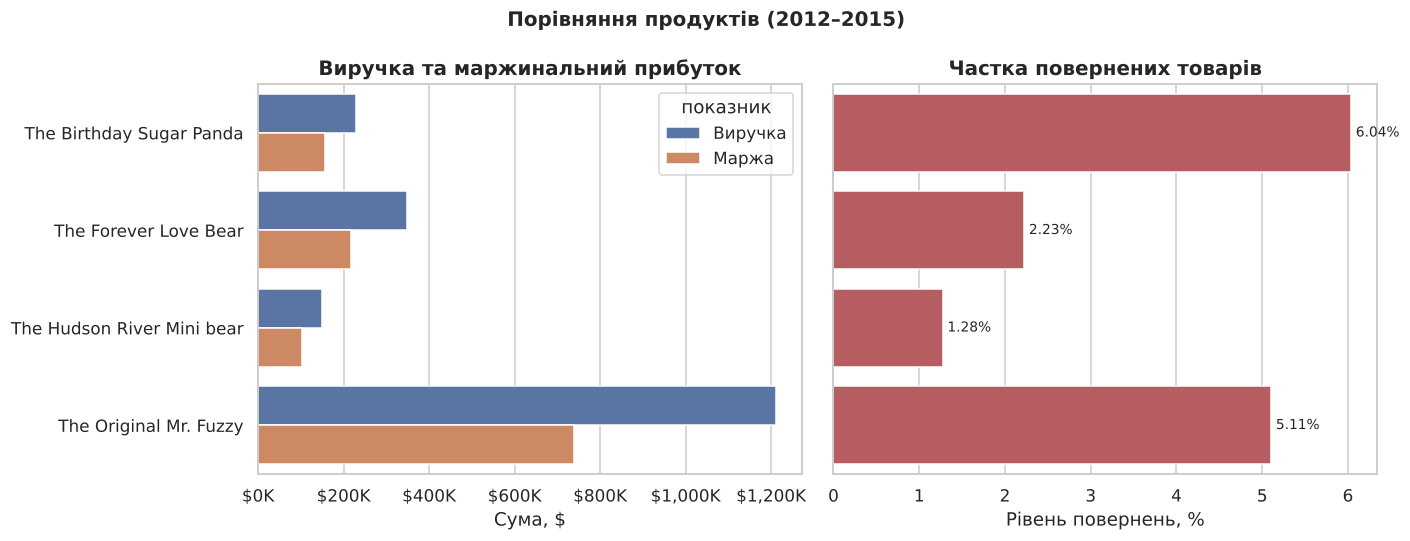

In [43]:
# Рис. 6. Продукти: виручка, маржа та рівень повернень
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bp = by_product.reset_index()
bp_long = bp.melt(id_vars="product_name", value_vars=["revenue", "margin"], var_name="показник", value_name="usd")
bp_long["показник"] = bp_long["показник"].map({"revenue": "Виручка", "margin": "Маржа"})
sns.barplot(data=bp_long, y="product_name", x="usd", hue="показник", ax=axes[0])
axes[0].set_title("Виручка та маржинальний прибуток")
axes[0].set_xlabel("Сума, $"); axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}K"))
sns.barplot(data=bp, y="product_name", x="refund_rate_pct", ax=axes[1], color="#C44E52")
axes[1].set_title("Частка повернених товарів")
axes[1].set_xlabel("Рівень повернень, %"); axes[1].set_ylabel(""); axes[1].set_yticklabels([])
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.2f}%", (p.get_width(), p.get_y() + p.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
fig.suptitle("Порівняння продуктів (2012–2015)", fontweight="bold", fontsize=13)
save_fig("06_products"); plt.show()

**Інтерпретація графіка.** Mr. Fuzzy домінує за виручкою й маржею, але разом із Birthday Sugar Panda має найвищий рівень повернень (5–6 %). Forever Love Bear і Mini bear повертають рідко (1,3–2,2 %), тому їх просування знижує втрати від повернень.

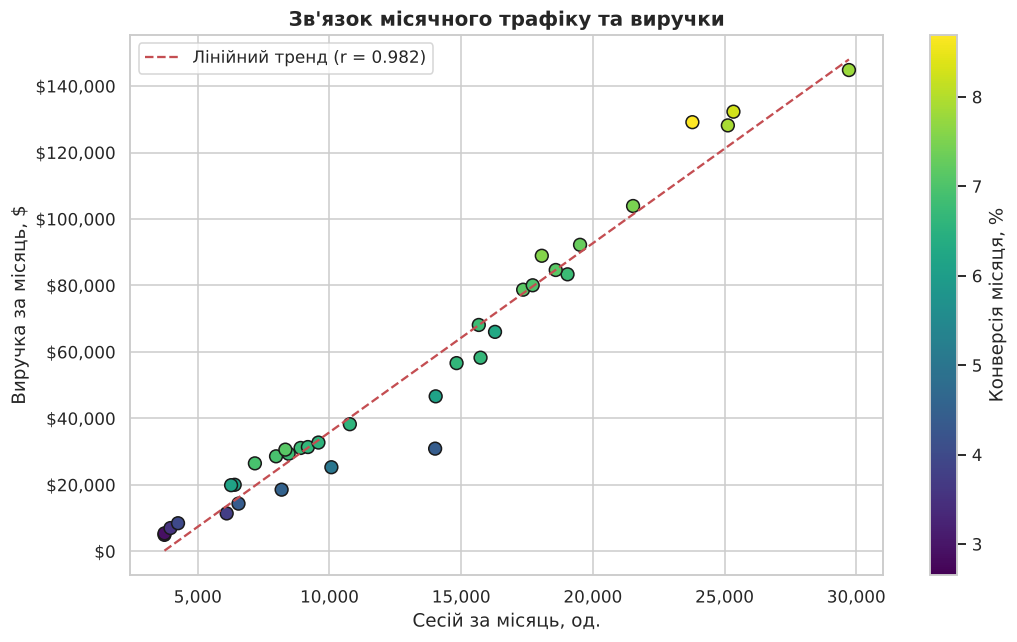

In [44]:
# Рис. 7. Діаграма розсіювання: місячний трафік vs виручка, колір — конверсія
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(monthly["sessions"], monthly["revenue"], c=monthly["cr_pct"], cmap="viridis", s=70, edgecolor="k")
z = np.polyfit(monthly["sessions"], monthly["revenue"], 1)
xs = np.linspace(monthly["sessions"].min(), monthly["sessions"].max(), 50)
ax.plot(xs, np.polyval(z, xs), "r--", label=f"Лінійний тренд (r = {monthly['sessions'].corr(monthly['revenue']):.3f})")
plt.colorbar(sc, label="Конверсія місяця, %")
ax.set_title("Зв'язок місячного трафіку та виручки")
ax.set_xlabel("Сесій за місяць, од."); ax.set_ylabel("Виручка за місяць, $")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.legend()
save_fig("07_scatter_sessions_revenue"); plt.show()

**Інтерпретація графіка.** Зв'язок місячного трафіку й виручки близький до лінійного (r = 0,982). Точки з вищою конверсією (жовто-зелені) лежать вище лінії тренду: за однакового трафіку пізніші місяці приносили більше виручки завдяки вищій конверсії та середньому чеку.

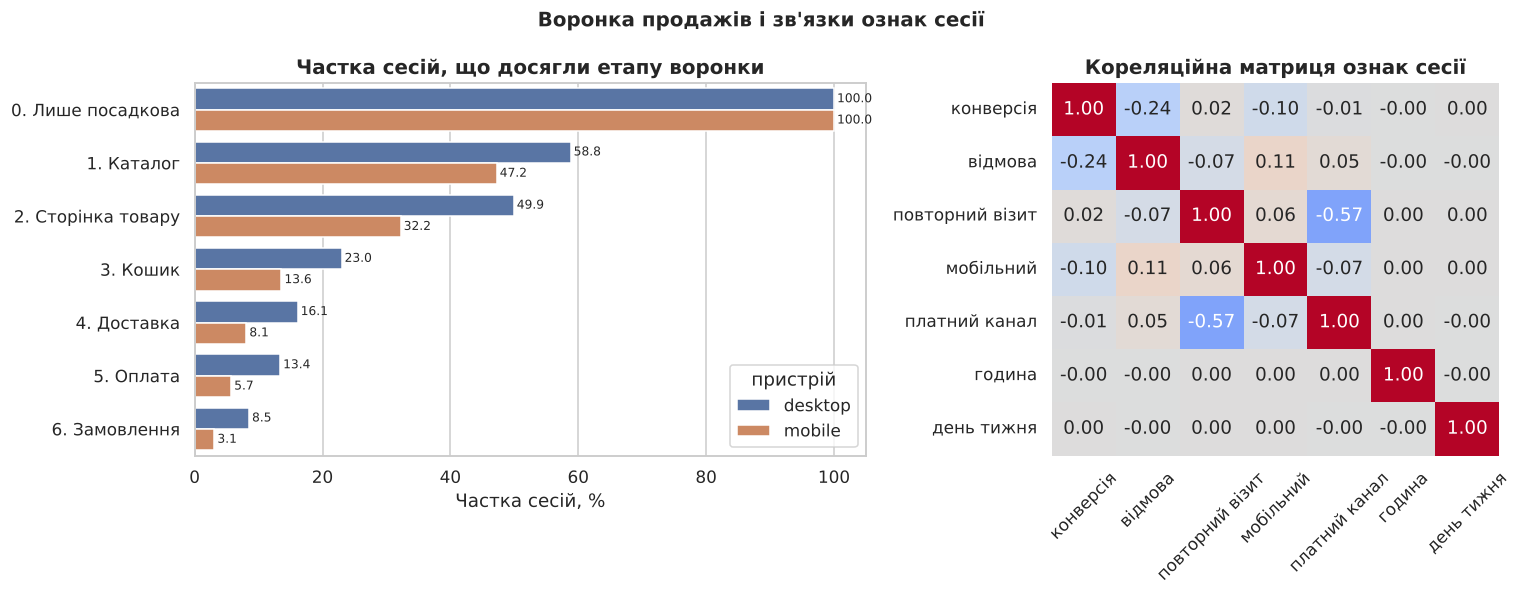

In [45]:
# Рис. 8. Воронка продажів за типом пристрою та кореляційна матриця
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [3, 2]})
fl = funnel_dev.xs("досягли етапу, %", axis=1, level=1).reset_index(names="етап") \
     .melt(id_vars="етап", var_name="пристрій", value_name="pct")
sns.barplot(data=fl, y="етап", x="pct", hue="пристрій", ax=axes[0], palette=["#4C72B0", "#DD8452"])
axes[0].set_title("Частка сесій, що досягли етапу воронки")
axes[0].set_xlabel("Частка сесій, %"); axes[0].set_ylabel("")
for p in axes[0].patches:
    if p.get_width() > 0:
        axes[0].annotate(f"{p.get_width():.1f}", (p.get_width(), p.get_y() + p.get_height() / 2),
                         xytext=(2, 0), textcoords="offset points", va="center", fontsize=8)
sns.heatmap(corr_session, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            ax=axes[1], cbar=False)
axes[1].set_title("Кореляційна матриця ознак сесії")
axes[1].tick_params(axis="x", rotation=45)
fig.suptitle("Воронка продажів і зв'язки ознак сесії", fontweight="bold", fontsize=13)
save_fig("08_funnel_correlation"); plt.show()

**Інтерпретація графіка.** Мобільні користувачі відстають від desktop уже на переході до каталогу, і розрив зростає на кожному етапі: до замовлення доходить 8,5 % desktop-сесій і лише 3,1 % мобільних. Кореляційна матриця показує, що з конверсією найбільше пов'язані відмова та мобільний пристрій, а час доби й день тижня — практично ні.

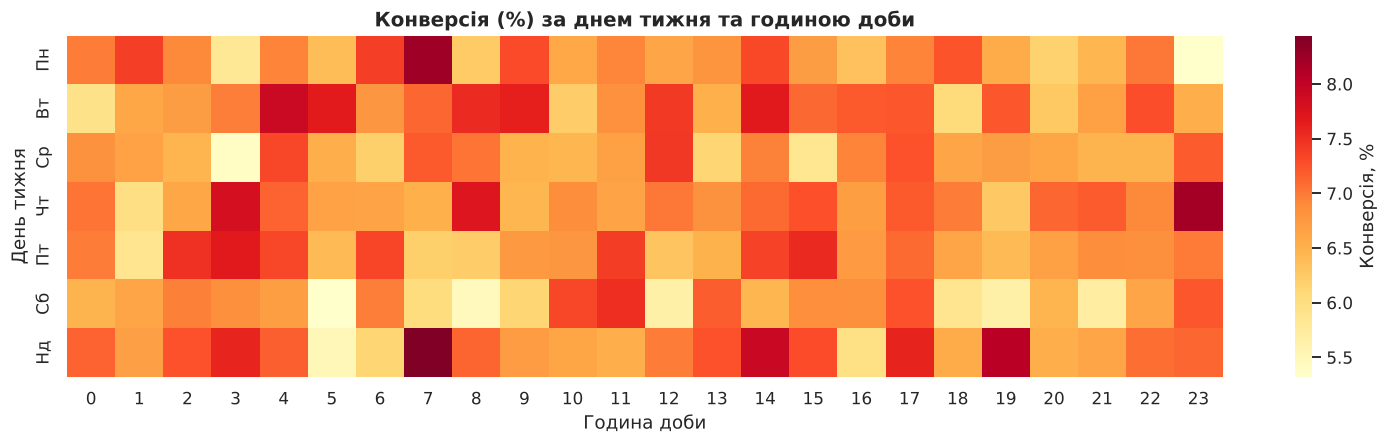

In [46]:
# Рис. 9. Конверсія за днем тижня і годиною (теплова карта зведеної таблиці)
wh = sess.pivot_table(index="weekday", columns="hour", values="is_converted", aggfunc="mean") * 100
wh.index = WD
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(wh, cmap="YlOrRd", cbar_kws={"label": "Конверсія, %"}, ax=ax)
ax.set_title("Конверсія (%) за днем тижня та годиною доби")
ax.set_xlabel("Година доби"); ax.set_ylabel("День тижня")
save_fig("09_weekday_hour_cr"); plt.show()

**Інтерпретація графіка.** Конверсія за годинами та днями коливається хаотично в межах 5,5–8,5 % без стійкого патерну; найбільші відхилення — в нічні години, де мало сесій. Отже, час доби майже не впливає на ймовірність покупки, і рекламу доцільно оптимізувати за обсягом трафіку (пік 11:00–15:00 у будні), а не за конверсією.

## 6. Підготовка даних для Tableau Public

Для дашборду формуємо агреговані таблиці, що зберігають розрізи, потрібні для інтерактивних фільтрів (дата, канал, пристрій, тип візиту, продукт).

In [47]:
# 6.1. Щоденні агрегати сесій (основне джерело дашборду)
daily = (sess.assign(date=sess["created_at"].dt.date)
         .groupby(["date", "channel", "utm_source", "utm_campaign", "device_type", "is_repeat_session"], observed=True)
         .agg(sessions=("website_session_id", "count"), bounces=("is_bounce", "sum"),
              orders=("is_converted", "sum"), revenue_usd=("price_usd", "sum"), margin_usd=("margin_usd", "sum"))
         .reset_index())
daily["is_repeat_session"] = daily["is_repeat_session"].map({True: "Повторний", False: "Перший"})
daily.to_csv(TABLEAU / "tableau_sessions_daily.csv", index=False, encoding="utf-8-sig")

# 6.2. Позиції замовлень з продуктами та поверненнями
tab_items = items_full.merge(orders[["order_id", "channel", "device_type"]], on="order_id", how="left")
tab_items[["order_item_id", "created_at", "order_id", "product_name", "is_primary_item", "price_usd", "cogs_usd",
           "margin_usd", "is_refunded", "refund_amount_usd", "net_revenue_usd", "channel", "device_type"]] \
    .to_csv(TABLEAU / "tableau_order_items.csv", index=False, encoding="utf-8-sig")

# 6.3. Результати обчислень
by_channel.to_csv(EXPORTS / "channel_metrics.csv", encoding="utf-8-sig")
by_campaign.to_csv(EXPORTS / "campaign_metrics.csv", encoding="utf-8-sig")
pivot_cr.to_csv(EXPORTS / "pivot_cr_channel_device.csv", encoding="utf-8-sig")
monthly.to_csv(EXPORTS / "monthly_metrics.csv", encoding="utf-8-sig")
by_product.to_csv(EXPORTS / "product_metrics.csv", encoding="utf-8-sig")
sess.drop(columns=["http_referer"]).to_parquet(PROCESSED / "sessions_enriched.parquet", index=False)

print(f"tableau_sessions_daily.csv: {len(daily):,} рядків | tableau_order_items.csv: {len(tab_items):,} рядків")
print("Перевірка: сесій у щоденних агрегатах =", f"{daily['sessions'].sum():,}", "| замовлень =", f"{daily['orders'].sum():,}")

tableau_sessions_daily.csv: 18,630 рядків | tableau_order_items.csv: 40,025 рядків
Перевірка: сесій у щоденних агрегатах = 472,871 | замовлень = 32,313


## 7. Висновки

1. **Канали (питання 1).** Платний небрендовий пошук — основне джерело трафіку (71,4 % сесій, 70 % замовлень), але конверсія в ньому нижча за середню (6,71 %). Найефективніші канали — брендовий (7,79 %) та органічний (7,51 %) пошук. Соцмережа socialbook неефективна (3,21 %), особливо пілотна кампанія `social_ad_1` (1,08 %).
2. **Пристрої (питання 2).** Конверсія на desktop (8,50 %) у 2,75 раза вища, ніж на mobile (3,09 %), за майже однакового середнього чека. Розрив зберігається в усіх каналах.
3. **Динаміка (питання 3).** За три роки місячний трафік зріс у 6,4 раза, замовлення — у 21 раз, конверсія — з 2,65 % до 8,69 %. Частка безкоштовного трафіку зросла з 9,2 % до 23,2 %, що зменшує залежність від платної реклами. Яскраво виражена сезонність: пік у листопаді–грудні.
4. **Продукти (питання 4).** Mr. Fuzzy дає 62,5 % виручки, але має високий рівень повернень (5,1 %). Крос-продаж збільшив середній чек з $49,99 до $63,80; Mini bear (рентабельність 68,4 %, повернень 1,3 %) — найкращий додатковий товар.
5. **Поведінка (питання 5).** Найбільше відвідувачів втрачається на посадковій сторінці (41–53 % не переходять далі) та між сторінкою товару й кошиком (переходить менше половини). Повторні візити конвертують краще (7,83 %). Час доби й день тижня на конверсію не впливають.

**Рекомендації:**
- оптимізувати мобільну версію сайту, насамперед сторінку товару, кошик і оформлення замовлення: навіть підвищення мобільної конверсії до половини desktop-рівня дасть близько 1 700 додаткових замовлень за аналогічний період;
- перерозподілити бюджет на користь bsearch nonbrand і брендових кампаній, а ставки в gsearch nonbrand для mobile знизити;
- зупинити пілотну кампанію socialbook `social_ad_1`; кампанію `desktop_targeted` продовжувати лише за умови позитивної окупності;
- поширити крос-продаж Mini bear і Forever Love Bear (низький рівень повернень); проаналізувати причини повернень Birthday Sugar Panda;
- концентрувати рекламні бюджети в будні в пікові години та на сезоні листопад–грудень.

**Обмеження дослідження:** набір даних не містить витрат на рекламу, тому неможливо розрахувати ROAS і вартість залучення; лендинги тестувалися в різні періоди й для різних пристроїв, тому їхнє порівняння має описовий характер; дані охоплюють лише один магазин і 2012–2015 рр.; кореляційний аналіз не встановлює причинно-наслідкових зв'язків.